# AgentAccess

**Authors:** Alexander Michels

In [1]:
import access
import geopandas as gpd
from IPython.display import Image
import math
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
from tqdm import tqdm
import sys
sys.path.append("../")
from agentaccess.Model import AgentAccess
# pandas gives warnings too often
pd.options.mode.chained_assignment = None

In [2]:
figsize=(10,10)

In [3]:
pop = gpd.read_file("../data/svi/SVI2018_US_tract.shp")
pop = pop[pop["STCNTY"] == "17031"]
pop = pop.to_crs("EPSG:4326")
print(len(pop))
pop.head()

1318


,ST,STATE,ST_ABBR,STCNTY,COUNTY,FIPS,LOCATION,AREA_SQMI,E_TOTPOP,M_TOTPOP,...,F_THEME4,F_TOTAL,E_UNINSUR,M_UNINSUR,EP_UNINSUR,MP_UNINSUR,E_DAYPOP,Shape_STAr,Shape_STLe,geometry
184,17,ILLINOIS,IL,17031,Cook,17031381700,"Census Tract 3817, Cook County, Illinois",0.075986,0,11,...,-999,-999,0,11,-999.0,-999.0,551,0.000021,0.020359,"POLYGON ((-87.62892 41.80919, -87.62608 41.809..."
185,17,ILLINOIS,IL,17031,Cook,17031980000,"Census Tract 9800, Cook County, Illinois",7.679554,0,11,...,-999,-999,0,11,-999.0,-999.0,38202,0.002171,0.222431,"POLYGON ((-87.94025 42.00717, -87.93895 42.006..."
186,17,ILLINOIS,IL,17031,Cook,17031980100,"Census Tract 9801, Cook County, Illinois",1.151272,0,11,...,-999,-999,0,11,-999.0,-999.0,6449,0.000323,0.076961,"POLYGON ((-87.76230 41.79274, -87.75251 41.792..."
12180,17,ILLINOIS,IL,17031,Cook,17031020100,"Census Tract 201, Cook County, Illinois",0.158747,3836,361,...,0,0,569,245,14.8,6.3,3714,0.000044,0.027301,"POLYGON ((-87.69020 42.01682, -87.69020 42.017..."
12181,17,ILLINOIS,IL,17031,Cook,17031020200,"Census Tract 202, Cook County, Illinois",0.479524,6739,510,...,0,1,628,396,9.3,6.0,3249,0.000135,0.051852,"POLYGON ((-87.70875 42.01550, -87.70866 42.019..."


In [4]:
pop["vehicle"] = pop["E_TOTPOP"] - pop["E_NOVEH"]

In [5]:
for x in pop["vehicle"]:
    assert x >= 0

In [6]:
# load the hospitals
hos = gpd.read_file("../data/hospitals/ContinentalHospitals.shp")
hos = hos[(hos["STATE"] == "IL") & (hos["COUNTY"] == "COOK")]
hos = hos[hos["BEDS"] >= 0]
print(sum(hos["BEDS"]))
hos = hos.to_crs("EPSG:4326")
print(len(hos))
hos.head()

18259
66


,OBJECTID,ID,NAME,ADDRESS,CITY,STATE,ZIP,ZIP4,TELEPHONE,TYPE,...,WEBSITE,STATE_ID,ALT_NAME,ST_FIPS,OWNER,TTL_STAFF,BEDS,TRAUMA,HELIPAD,geometry
507,1513,0003460644,UHS HARTGROVE HOSPITAL,5730 WEST ROOSEVELT ROAD,CHICAGO,IL,60644,NOT AVAILABLE,(773) 413-1700,PSYCHIATRIC,...,http://www.hartgrovehospital.com,0005454,NOT AVAILABLE,17,PROPRIETARY,-999,128,NOT AVAILABLE,N,POINT (-87.76746 41.86633)
508,1514,0001860612,JESSE BROWN VA MEDICAL CENTER - VA CHICAGO HEA...,820 S DAMEN STREET,CHICAGO,IL,60612,NOT AVAILABLE,(312) 569-8387,MILITARY,...,http://www.chicago.va.gov/,14003F,NOT AVAILABLE,17,GOVERNMENT - FEDERAL,-999,240,NOT AVAILABLE,N,POINT (-87.67704 41.87074)
509,1515,0003160463,PALOS COMMUNITY HOSPITAL,12251 SOUTH 80TH AVENUE,PALOS HEIGHTS,IL,60464,NOT AVAILABLE,(708) 923-4000,GENERAL ACUTE CARE,...,http://www.paloscommunityhospital.org,140062,NOT AVAILABLE,17,NON-PROFIT,-999,377,NOT AVAILABLE,Y,POINT (-87.81344 41.66921)
510,1516,0003660628,ROSELAND COMMUNITY HOSPITAL,45 W 111TH STREET,CHICAGO,IL,60628,NOT AVAILABLE,(773) 995-3000,GENERAL ACUTE CARE,...,http://www.roselandhospital.org,140068,NOT AVAILABLE,17,NON-PROFIT,-999,115,NOT AVAILABLE,N,POINT (-87.62536 41.69223)
511,1517,0002360302,WEST SUBURBAN MEDICAL CENTER,3 ERIE COURT,OAK PARK,IL,60302,NOT AVAILABLE,(708) 383-6200,GENERAL ACUTE CARE,...,http://www.westsuburbanmc.com/Home.aspx,140049,NOT AVAILABLE,17,PROPRIETARY,-999,172,NOT AVAILABLE,N,POINT (-87.77618 41.89140)


<AxesSubplot:>

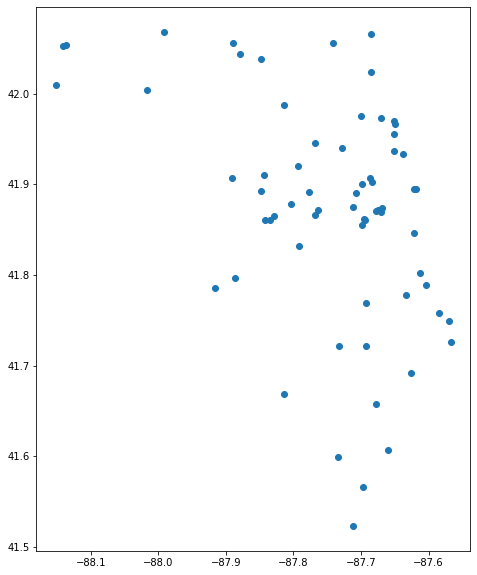

In [7]:
hos.plot(figsize=figsize)

In [8]:
# get car travel times
car = pd.read_csv("../data/travel_times/17031-output-TRACT-CAR.csv")
car["origin"] = car["origin"].astype(str)
car["destination"] = car["destination"].astype(str)
car = car.rename(columns={"minutes": "car"})
print(len(car))
car.head()

3780024


,origin,destination,car
0,17031010100,17007010100,101.35
1,17031010100,17007010200,96.10
2,17031010100,17007010300,96.43
3,17031010100,17007010400,96.17
4,17031010100,17007010500,107.13


In [9]:
# get the transit/walking times
transit = pd.read_csv("../data/travel_times/17031-output-TRACT-TRANSIT,WALK.csv")
transit["origin"] = transit["origin"].astype(str)
transit["destination"] = transit["destination"].astype(str)
transit = transit.rename(columns={"minutes": "transit"})
print(len(transit))
transit.head()

2853575


,origin,destination,transit
0,17031010100,17007010100,541.58
1,17031010100,17007010200,542.43
2,17031010100,17007010300,561.87
3,17031010100,17007010400,567.78
4,17031010100,17007010500,534.08


In [10]:
# get the walking times
walk = pd.read_csv("../data/travel_times/17031-output-TRACT-WALK.csv")
walk["origin"] = walk["origin"].astype(str)
walk["destination"] = walk["destination"].astype(str)
walk = walk.rename(columns={"minutes": "walk"})
print(len(walk))
walk.head()

234772


,origin,destination,walk
0,17031010100,17031010100,0.17
1,17031010100,17031010201,19.35
2,17031010100,17031010202,10.35
3,17031010100,17031010300,10.83
4,17031010100,17031010400,29.22


In [11]:
travel_times = pd.merge(car, transit, how="outer",
                       left_on=["origin", "destination"],
                       right_on=["origin", "destination"])
print(len(travel_times))
travel_times.head()

3782602


,origin,destination,car,transit
0,17031010100,17007010100,101.35,541.58
1,17031010100,17007010200,96.10,542.43
2,17031010100,17007010300,96.43,561.87
3,17031010100,17007010400,96.17,567.78
4,17031010100,17007010500,107.13,534.08


In [12]:
travel_times = pd.merge(travel_times, walk, how="outer",
                       left_on=["origin", "destination"],
                       right_on=["origin", "destination"])
print(len(travel_times))
travel_times.head()

3782602


,origin,destination,car,transit,walk
0,17031010100,17007010100,101.35,541.58,NaN
1,17031010100,17007010200,96.10,542.43,NaN
2,17031010100,17007010300,96.43,561.87,NaN
3,17031010100,17007010400,96.17,567.78,NaN
4,17031010100,17007010500,107.13,534.08,NaN


In [13]:
time_steps = 10

In [14]:
# intialize our model
# def __init__(self, demand_df, demand_geoid, demand_field, supply_df, supply_geoid, supply_field,
#              cost_df, cost_origin, cost_dest, cost_field, time_steps, memory=0, pop_per_agent=1000, top_k=0):
model = AgentAccess(
    pop,
    "FIPS",
    "E_TOTPOP",
    hos,
    "who cares",
    "BEDS",
    travel_times,
    "origin",
    "destination",
    ["car", "transit"],
    time_steps,
    cost_function="gravity",
#     cost_prop=[0.7, 0.2, 0.1],
    cost_prop_fields=["vehicle", "E_NOVEH"],
    memory=0,
    pop_per_agent=1000,
    top_k=5,
    output_path="../outputs/"
)

[0 0]
[0.5, 0.5]
[0 0]
[0.5, 0.5]
[0 0]
[0.5, 0.5]
[3586 250]
[0.9348279457768509, 0.06517205422314912]
[6648 91]
[0.9864965128357323, 0.013503487164267695]
[4036 200]
[0.9527856468366384, 0.047214353163361665]
[4451 283]
[0.9402196873679763, 0.05978031263202366]
[1732 16]
[0.9908466819221968, 0.009153318077803204]
[5885 227]
[0.9628599476439791, 0.03714005235602094]
[2760 301]
[0.9016661221822934, 0.09833387781770664]
[6354 537]
[0.9220722681758816, 0.07792773182411841]
[2899 26]
[0.9911111111111112, 0.008888888888888889]
[3135 212]
[0.9366596952494771, 0.06334030475052285]
[4884 385]
[0.9269311064718163, 0.07306889352818371]
[2297 217]
[0.9136833731105808, 0.08631662688941925]
[2527 204]
[0.925302087147565, 0.074697912852435]
[5115 316]
[0.941815503590499, 0.05818449640950101]
[2670 53]
[0.9805361733382298, 0.019463826661770108]
[5793 276]
[0.9545229856648542, 0.045477014335145824]
[1961 216]
[0.9007808911345889, 0.09921910886541112]
[1548 62]
[0.9614906832298137, 0.03850931677018633

[1630 95]
[0.9449275362318841, 0.05507246376811594]
[2176 114]
[0.9502183406113537, 0.04978165938864629]
[2647 111]
[0.9597534445250181, 0.04024655547498187]
[2455 100]
[0.9608610567514677, 0.03913894324853229]
[4419 293]
[0.9378183361629882, 0.06218166383701188]
[1747 95]
[0.9484256243213898, 0.05157437567861021]
[3435 243]
[0.933931484502447, 0.06606851549755302]
[4072 341]
[0.922728302741899, 0.07727169725810107]
[3204 262]
[0.9244085401038661, 0.07559145989613388]
[1892 89]
[0.9550731953558809, 0.044926804644119134]
[1410 99]
[0.9343936381709742, 0.06560636182902585]
[1495 113]
[0.929726368159204, 0.07027363184079602]
[2130 100]
[0.9551569506726457, 0.04484304932735426]
[7603 181]
[0.9767471736896197, 0.023252826310380267]
[4379 124]
[0.9724628025760604, 0.027537197423939595]
[5214 260]
[0.9525027402265254, 0.047497259773474604]
[5889 209]
[0.965726467694326, 0.03427353230567399]
[5087 203]
[0.9616257088846881, 0.03837429111531191]
[6978 179]
[0.9749895207489171, 0.0250104792510828

[6428 123]
[0.9812242405739582, 0.018775759426041826]
[6461 15]
[0.9976837554045708, 0.0023162445954292774]
[5192 31]
[0.9940647137660349, 0.005935286233965154]
[2684 14]
[0.9948109710896961, 0.005189028910303929]
[4179 45]
[0.9893465909090909, 0.01065340909090909]
[6968 167]
[0.976594253679047, 0.023405746320953047]
[6308 72]
[0.9887147335423198, 0.01128526645768025]
[5216 34]
[0.9935238095238095, 0.0064761904761904765]
[4809 23]
[0.9952400662251656, 0.004759933774834437]
[4084 98]
[0.9765662362505978, 0.0234337637494022]
[4278 100]
[0.9771585198720877, 0.02284148012791229]
[3099 42]
[0.9866284622731614, 0.013371537726838587]
[3618 82]
[0.9778378378378378, 0.02216216216216216]
[3850 106]
[0.9732052578361982, 0.02679474216380182]
[4924 116]
[0.976984126984127, 0.023015873015873017]
[3825 121]
[0.9693360364926508, 0.030663963507349214]
[3909 89]
[0.9777388694347173, 0.02226113056528264]
[4398 59]
[0.9867623962306484, 0.013237603769351581]
[5039 55]
[0.9892029839026305, 0.010797016097369

[3492 288]
[0.9238095238095239, 0.0761904761904762]
[5281 224]
[0.9593097184377838, 0.040690281562216164]
[1939 81]
[0.9599009900990099, 0.0400990099009901]
[1757 101]
[0.9456404736275565, 0.05435952637244349]
[2613 172]
[0.9382405745062836, 0.06175942549371634]
[2175 116]
[0.9493670886075949, 0.05063291139240506]
[4156 263]
[0.9404842724598326, 0.05951572754016746]
[2693 188]
[0.9347448802499132, 0.06525511975008677]
[2957 219]
[0.9310453400503779, 0.06895465994962216]
[2373 115]
[0.9537781350482315, 0.04622186495176849]
[3762 110]
[0.9715909090909091, 0.028409090909090908]
[2929 206]
[0.9342902711323764, 0.0657097288676236]
[3171 187]
[0.9443120905300775, 0.055687909469922574]
[3897 228]
[0.9447272727272727, 0.05527272727272727]
[2474 143]
[0.9453572793274742, 0.05464272067252579]
[3481 285]
[0.9243228890069038, 0.07567711099309612]
[5126 346]
[0.9367690058479532, 0.06323099415204679]
[5071 277]
[0.9482049364248317, 0.05179506357516829]
[5702 429]
[0.9300277279399771, 0.0699722720600

[3286 0]
[1.0, 0.0]
[5076 135]
[0.9740932642487047, 0.025906735751295335]
[6058 184]
[0.9705222685036847, 0.029477731496315284]
[5356 9]
[0.9983224603914259, 0.0016775396085740913]
[5074 312]
[0.942072038618641, 0.057927961381359076]
[6514 151]
[0.977344336084021, 0.022655663915978994]
[2581 41]
[0.9843630816170862, 0.015636918382913808]
[2463 90]
[0.9647473560517039, 0.03525264394829612]
[2563 63]
[0.976009139375476, 0.02399086062452399]
[5457 195]
[0.9654989384288747, 0.034501061571125265]
[8768 172]
[0.9807606263982103, 0.01923937360178971]
[5884 74]
[0.9875797247398456, 0.012420275260154415]
[3297 72]
[0.9786286731967943, 0.0213713268032057]
[3457 124]
[0.9653728008936051, 0.03462719910639486]
[3830 61]
[0.9843227961963505, 0.015677203803649446]
[2755 62]
[0.9779907703230387, 0.022009229676961305]
[2326 39]
[0.9835095137420719, 0.01649048625792812]
[6573 35]
[0.9947033898305084, 0.005296610169491525]
[5753 173]
[0.9708066149173136, 0.029193385082686468]
[5863 391]
[0.93748001279181

[1388 100]
[0.9327956989247311, 0.06720430107526881]
[1067 411]
[0.7219215155615697, 0.2780784844384303]
[1077 186]
[0.8527315914489311, 0.14726840855106887]
[1157 159]
[0.8791793313069909, 0.12082066869300911]
[696 145]
[0.8275862068965517, 0.1724137931034483]
[5083 1364]
[0.7884287265394757, 0.21157127346052426]
[813 178]
[0.8203834510595358, 0.17961654894046417]
[4124 1894]
[0.6852775008308408, 0.3147224991691592]
[2725 532]
[0.8366595026097636, 0.16334049739023643]
[3292 313]
[0.9131761442441054, 0.08682385575589459]
[2682 207]
[0.9283489096573209, 0.07165109034267912]
[4341 380]
[0.9195085786909553, 0.0804914213090447]
[3808 262]
[0.9356265356265356, 0.06437346437346438]
[2208 215]
[0.9112670243499794, 0.08873297565002064]
[3678 265]
[0.9327922901344154, 0.06720770986558458]
[1026 155]
[0.8687552921253175, 0.13124470787468248]
[5013 378]
[0.9298831385642737, 0.07011686143572621]
[9906 3473]
[0.740414081769938, 0.25958591823006205]
[3798 1125]
[0.7714808043875686, 0.228519195612431

In [15]:
model.run_model()

Running Model: 100%|████████████████████████████| 10/10 [05:37<00:00, 33.77s/it]


In [16]:
model.cost_df.head()

car  transit    walk
origin      destination                        
17031010100 17031031000  21.53    35.05   75.35
            17031031300  21.02    30.28   81.10
            17031031400  21.70    37.02  102.52
            17031032100  22.13    26.77   95.38
            17031040300  19.10    40.37   90.75

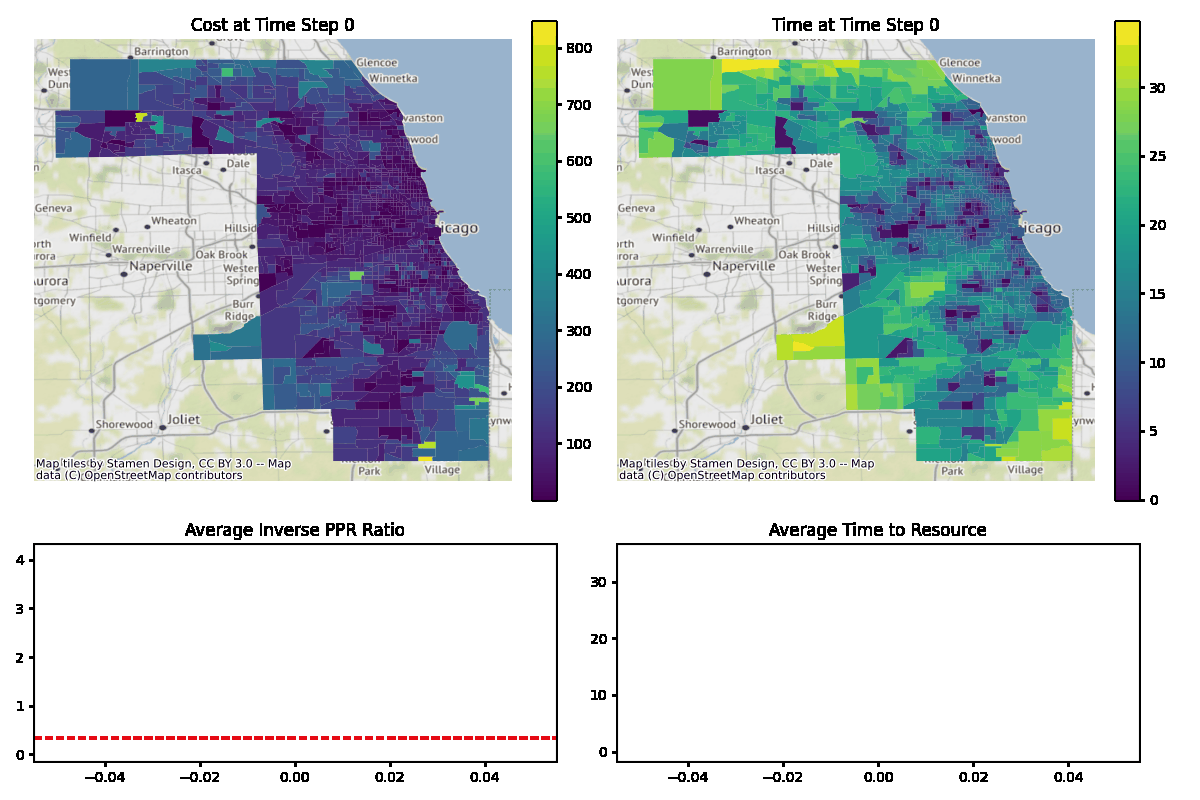

In [17]:
Image(filename=os.path.join(model.output_dir, "movie.gif"))

In [18]:
model.cost_df.head()

car  transit    walk
origin      destination                        
17031010100 17031031000  21.53    35.05   75.35
            17031031300  21.02    30.28   81.10
            17031031400  21.70    37.02  102.52
            17031032100  22.13    26.77   95.38
            17031040300  19.10    40.37   90.75

In [19]:
model.demand_df.head()

,ID,GEOID,Cost Field,Choice 0,Cost 0,Choice 1,Cost 1,Choice 2,Cost 2,Choice 3,...,Choice 5,Cost 5,Choice 6,Cost 6,Choice 7,Cost 7,Choice 8,Cost 8,Choice 9,Cost 9
0,0,17031381700,transit,17031381900,98.518764,17031841000,273.455488,17031836200,220.161525,17031836200,...,17031841000,245.958859,17031381900,374.379771,17031836200,241.628522,17031841000,243.617113,17031836200,242.449482
1,1,17031980000,car,17031100400,144.668793,17031081401,118.363235,17031100400,124.862977,17031838100,...,17031805902,183.650015,17031805902,184.528723,17031100400,166.749409,17031805901,255.963082,17031811302,289.349375
2,2,17031980100,transit,17031815400,657.451635,17031838200,163.176001,17031822102,486.567296,17031822102,...,17031081401,688.966886,17031838200,706.671068,17031822102,647.107293,17031815400,615.544157,17031821800,774.428981
3,3,17031020100,car,17031810200,7.909400,17031810200,10.945789,17031810200,8.134027,17031810200,...,17031040300,96.298961,17031810200,8.753284,17031810200,8.793930,17031810200,8.949940,17031810200,8.926230
4,4,17031020100,car,17031810200,7.909400,17031808800,29.223741,17031031400,115.347600,17031810200,...,17031040300,96.298961,17031808800,51.908837,17031810200,8.793930,17031810200,8.949940,17031810200,8.926230


In [20]:
model.supply_df.head()

,geometry,Supply,Demand 0,D/S Ratio 0,Demand 1,D/S Ratio 1,Demand 2,D/S Ratio 2,Demand 3,D/S Ratio 3,...,Demand 5,D/S Ratio 5,Demand 6,D/S Ratio 6,Demand 7,D/S Ratio 7,Demand 8,D/S Ratio 8,Demand 9,D/S Ratio 9
GEOID,,,,,,,,,,,,,,,,,,,,,
17031031000,"POLYGON ((-87.67441 41.97610, -87.66961 41.976...",189,91,0.481481,39,0.206349,91,0.481481,83,0.439153,...,81,0.428571,86,0.455026,77,0.407407,76,0.402116,84,0.444444
17031031300,"POLYGON ((-87.65499 41.97640, -87.65428 41.976...",115,64,0.556522,22,0.191304,42,0.365217,52,0.452174,...,48,0.417391,41,0.356522,46,0.400000,47,0.408696,42,0.365217
17031031400,"POLYGON ((-87.65012 41.96916, -87.64964 41.969...",184,55,0.298913,37,0.201087,89,0.483696,66,0.358696,...,53,0.288043,55,0.298913,49,0.266304,64,0.347826,66,0.358696
17031032100,"POLYGON ((-87.65634 41.96176, -87.65475 41.961...",134,93,0.694030,20,0.149254,56,0.417910,53,0.395522,...,65,0.485075,56,0.417910,72,0.537313,59,0.440299,47,0.350746
17031040300,"POLYGON ((-87.70582 41.98309, -87.70401 41.983...",279,151,0.541219,63,0.225806,94,0.336918,112,0.401434,...,104,0.372760,118,0.422939,115,0.412186,112,0.401434,130,0.465950


In [21]:
model.spatial_units_df.head()

,Demand,geometry,Cost 0,D/S Ratio 0,Time 0,Cost 1,D/S Ratio 1,Time 1,Cost 2,D/S Ratio 2,...,Time 6,Cost 7,D/S Ratio 7,Time 7,Cost 8,D/S Ratio 8,Time 8,Cost 9,D/S Ratio 9,Time 9
GEOID,,,,,,,,,,,,,,,,,,,,,
17031381700,0,"POLYGON ((-87.62892 41.80919, -87.62608 41.809...",98.518764,4.120000,10.7300,273.455488,0.066508,12.650000,220.161525,0.237435,...,10.730000,241.628522,0.322357,16.300000,243.617113,0.344418,12.650000,242.449482,0.301560,16.300000
17031980000,0,"POLYGON ((-87.94025 42.00717, -87.93895 42.006...",144.668793,0.462687,21.0700,118.363235,0.644799,37.570000,124.862977,0.522388,...,26.080000,166.749409,0.355721,21.070000,255.963082,0.513274,21.720000,289.349375,0.196078,35.670000
17031980100,0,"POLYGON ((-87.76230 41.79274, -87.75251 41.792...",657.451635,0.277628,25.2800,163.176001,1.060862,26.280000,486.567296,0.326023,...,26.280000,647.107293,0.298246,22.930000,615.544157,0.315364,25.280000,774.428981,0.427083,29.880000
17031020100,3836,"POLYGON ((-87.69020 42.01682, -87.69020 42.017...",28.223339,0.361490,7.7675,20.084765,0.227447,10.685000,44.763548,0.344368,...,10.455000,19.706098,0.354478,7.767500,50.937407,0.285141,12.410000,8.926230,0.344262,4.850000
17031020200,6739,"POLYGON ((-87.70875 42.01550, -87.70866 42.019...",49.506427,0.414245,11.2400,31.228180,0.340658,12.697143,17.209180,0.360656,...,10.271429,24.348792,0.378203,8.585714,60.146001,0.325160,12.915714,73.314454,0.333738,13.822857


In [22]:
def normalize_columns(df, columns, to_flip=[]):
    for column in columns:
        df[column] = (df[column] - df[column].min()) / (df[column].max() - df[column].min())
        if column in to_flip:
            df[column] = 1 - df[column]
    return df

def average_columns(df, new_column, columns_to_average):
    df[new_column] = df[columns_to_average].mean(axis=1)
    return df

In [23]:
last_portion = 2
df = average_columns(model.spatial_units_df, "D/S Ratio", [f"D/S Ratio {x}" for x  in range(time_steps//last_portion, time_steps)])
df = average_columns(df, "Time", [f"Time {x}" for x  in range(time_steps//last_portion, time_steps)])
df = average_columns(df, "Cost", [f"Cost {x}" for x  in range(time_steps//last_portion, time_steps)])
df = df[["D/S Ratio", "Time", "Cost", "geometry"]]
df.head()

,D/S Ratio,Time,Cost,geometry
GEOID,,,,
17031381700,0.442902,13.726000,269.606749,"POLYGON ((-87.62892 41.80919, -87.62608 41.809..."
17031980000,0.315899,26.124000,216.048121,"POLYGON ((-87.94025 42.00717, -87.93895 42.006..."
17031980100,0.296897,25.948000,686.543677,"POLYGON ((-87.76230 41.79274, -87.75251 41.792..."
17031020100,0.340272,9.141500,34.656362,"POLYGON ((-87.69020 42.01682, -87.69020 42.017..."
17031020200,0.344593,11.508571,49.773632,"POLYGON ((-87.70875 42.01550, -87.70866 42.019..."


In [24]:
cols = ["D/S Ratio", "Time", "Cost"]
model_result = df
# model_result = normalize_columns(df, columns=cols)
model_result.head()

,D/S Ratio,Time,Cost,geometry
GEOID,,,,
17031381700,0.442902,13.726000,269.606749,"POLYGON ((-87.62892 41.80919, -87.62608 41.809..."
17031980000,0.315899,26.124000,216.048121,"POLYGON ((-87.94025 42.00717, -87.93895 42.006..."
17031980100,0.296897,25.948000,686.543677,"POLYGON ((-87.76230 41.79274, -87.75251 41.792..."
17031020100,0.340272,9.141500,34.656362,"POLYGON ((-87.69020 42.01682, -87.69020 42.017..."
17031020200,0.344593,11.508571,49.773632,"POLYGON ((-87.70875 42.01550, -87.70866 42.019..."


<AxesSubplot:>

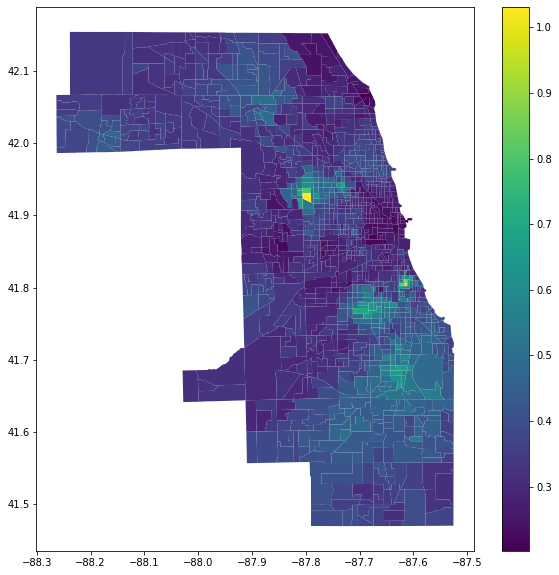

In [25]:
model_result.plot(column="D/S Ratio", figsize=figsize, legend=True)

<AxesSubplot:>

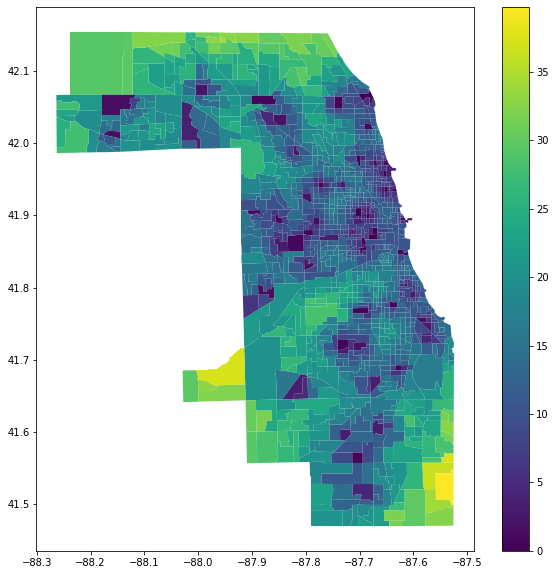

In [26]:
model_result.plot(column="Time", figsize=figsize, legend=True)

<AxesSubplot:>

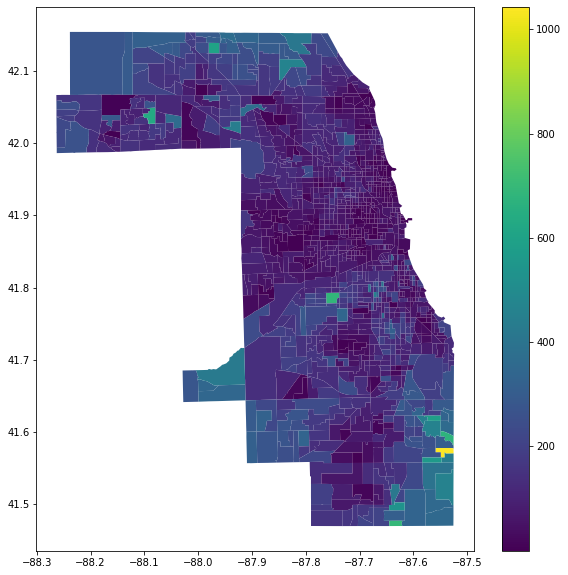

In [27]:
model_result.plot(column="Cost", figsize=figsize, legend=True)

In [28]:
acc = gpd.read_file("../data/accessibility/CookHospitals.gpkg")
acc = acc.set_index("geoid")
cols = list(acc.columns)
cols.remove('geometry')
# acc = normalize_columns(acc, cols)
print(len(acc))
acc.head()

1318


,gravity_BEDS,fca_BEDS,fca60_BEDS,fca90_BEDS,2sfca_BEDS,2sfca30_BEDS,2sfca60_BEDS,g2sfca_BEDS,3sfca_BEDS,raam_BEDS,raam30_BEDS,geometry
geoid,,,,,,,,,,,,
17031010100,28947.351633,0.005191,0.003693,0.003495,0.002790,0.003988,0.002484,0.002699,0.005337,1.151754,1.353203,"POLYGON ((-87.66507 42.01926, -87.66604 42.019..."
17031010201,30688.468786,0.004612,0.003705,0.003495,0.003022,0.004222,0.002714,0.002867,0.005148,1.115558,1.278645,"POLYGON ((-87.68281 42.01947, -87.68163 42.019..."
17031010202,29613.408700,0.004703,0.003669,0.003495,0.002956,0.004354,0.002645,0.002820,0.005539,1.173011,1.375311,"POLYGON ((-87.67464 42.01263, -87.67547 42.012..."
17031010300,29395.681764,0.004847,0.003738,0.003495,0.002931,0.004445,0.002648,0.002814,0.005940,1.187285,1.428868,"POLYGON ((-87.66383 42.01612, -87.66340 42.015..."
17031010400,31556.255500,0.004244,0.003601,0.003495,0.003050,0.002963,0.003023,0.003120,0.004095,1.126623,1.375371,"POLYGON ((-87.66156 42.01041, -87.66108 42.009..."


In [29]:
comparison = gpd.GeoDataFrame(df[["D/S Ratio", "Time", "Cost"]].merge(acc, left_index=True, right_index=True))
print(len(comparison))
comparison.head()

1318


,D/S Ratio,Time,Cost,gravity_BEDS,fca_BEDS,fca60_BEDS,fca90_BEDS,2sfca_BEDS,2sfca30_BEDS,2sfca60_BEDS,g2sfca_BEDS,3sfca_BEDS,raam_BEDS,raam30_BEDS,geometry
17031381700,0.442902,13.726000,269.606749,39837.372655,0.004058,0.003495,0.003495,0.003801,0.004707,0.004417,0.004737,0.003667,NaN,NaN,"POLYGON ((-87.62608 41.80924, -87.62603 41.807..."
17031980000,0.315899,26.124000,216.048121,28311.101254,0.002253,0.003604,0.003495,0.003613,0.000744,0.003538,0.002564,0.001266,NaN,NaN,"POLYGON ((-87.87787 41.97304, -87.87675 41.969..."
17031980100,0.296897,25.948000,686.543677,33166.883503,0.004231,0.003634,0.003495,0.003801,0.002793,0.003975,0.003692,0.002473,NaN,NaN,"POLYGON ((-87.74836 41.77831, -87.75322 41.778..."
17031020100,0.340272,9.141500,34.656362,31084.752206,0.004443,0.003671,0.003495,0.003123,0.004222,0.002825,0.002925,0.004924,1.110285,1.265311,"POLYGON ((-87.69023 42.01411, -87.69020 42.016..."
17031020200,0.344593,11.508571,49.773632,30644.100285,0.003132,0.003576,0.003495,0.003228,0.004036,0.003269,0.003030,0.004207,1.149850,1.340311,"POLYGON ((-87.69023 42.01411, -87.69025 42.012..."


In [30]:
corr = comparison.corr(method='pearson')
corr.style.background_gradient(cmap='coolwarm', vmin=-1, vmax=1)

,D/S Ratio,Time,Cost,gravity_BEDS,fca_BEDS,fca60_BEDS,fca90_BEDS,2sfca_BEDS,2sfca30_BEDS,2sfca60_BEDS,g2sfca_BEDS,3sfca_BEDS,raam_BEDS,raam30_BEDS
D/S Ratio,1.000000,-0.070245,0.092851,-0.324330,-0.172004,0.133703,-0.013473,-0.178523,-0.388688,-0.223251,-0.299341,-0.389579,0.364254,0.344812
Time,-0.070245,1.000000,0.804379,-0.671091,-0.454769,0.304174,0.110420,-0.425275,-0.594617,-0.488001,-0.543841,-0.696270,0.820308,0.852520
Cost,0.092851,0.804379,1.000000,-0.546111,-0.433538,0.316212,0.151922,-0.418530,-0.553533,-0.466522,-0.510917,-0.639456,0.727230,0.755528
gravity_BEDS,-0.324330,-0.671091,-0.546111,1.000000,0.505141,-0.507826,-0.112050,0.673174,0.811063,0.792053,0.859635,0.604103,-0.810579,-0.803311
fca_BEDS,-0.172004,-0.454769,-0.433538,0.505141,1.000000,-0.381211,-0.056597,0.563385,0.521101,0.582382,0.583030,0.547938,-0.597256,-0.580058
fca60_BEDS,0.133703,0.304174,0.316212,-0.507826,-0.381211,1.000000,0.098476,-0.597425,-0.413258,-0.654259,-0.607977,-0.206730,0.428190,0.401780
fca90_BEDS,-0.013473,0.110420,0.151922,-0.112050,-0.056597,0.098476,1.000000,-0.278139,-0.079728,-0.170018,-0.133935,-0.048237,0.077134,0.062819
2sfca_BEDS,-0.178523,-0.425275,-0.418530,0.673174,0.563385,-0.597425,-0.278139,1.000000,0.583306,0.909718,0.820181,0.329221,-0.572880,-0.549919
2sfca30_BEDS,-0.388688,-0.594617,-0.553533,0.811063,0.521101,-0.413258,-0.079728,0.583306,1.000000,0.769576,0.888566,0.791142,-0.772344,-0.776946
2sfca60_BEDS,-0.223251,-0.488001,-0.466522,0.792053,0.582382,-0.654259,-0.170018,0.909718,0.769576,1.000000,0.960267,0.438506,-0.661083,-0.643517


In [31]:
corr = comparison.corr(method='kendall')
corr.style.background_gradient(cmap='coolwarm', vmin=-1, vmax=1)

,D/S Ratio,Time,Cost,gravity_BEDS,fca_BEDS,fca60_BEDS,fca90_BEDS,2sfca_BEDS,2sfca30_BEDS,2sfca60_BEDS,g2sfca_BEDS,3sfca_BEDS,raam_BEDS,raam30_BEDS
D/S Ratio,1.000000,0.017265,0.149475,-0.241868,-0.125270,0.215617,0.015090,-0.262176,-0.310738,-0.233236,-0.250941,-0.304311,0.307757,0.305489
Time,0.017265,1.000000,0.737951,-0.505898,-0.310283,0.199066,0.099289,-0.288292,-0.421753,-0.297184,-0.353235,-0.506880,0.622495,0.651446
Cost,0.149475,0.737951,1.000000,-0.504046,-0.310492,0.234347,0.103394,-0.322560,-0.448756,-0.316520,-0.372499,-0.522785,0.625092,0.651295
gravity_BEDS,-0.241868,-0.505898,-0.504046,1.000000,0.418928,-0.451956,-0.142672,0.678072,0.648677,0.740050,0.797307,0.481011,-0.663228,-0.656957
fca_BEDS,-0.125270,-0.310283,-0.310492,0.418928,1.000000,-0.240970,-0.070710,0.403864,0.361909,0.325709,0.375433,0.387962,-0.422593,-0.403532
fca60_BEDS,0.215617,0.199066,0.234347,-0.451956,-0.240970,1.000000,0.094149,-0.391995,-0.365058,-0.476591,-0.487398,-0.227840,0.325052,0.318597
fca90_BEDS,0.015090,0.099289,0.103394,-0.142672,-0.070710,0.094149,1.000000,-0.152429,-0.096347,-0.143052,-0.138186,-0.045983,0.096019,0.082770
2sfca_BEDS,-0.262176,-0.288292,-0.322560,0.678072,0.403864,-0.391995,-0.152429,1.000000,0.539095,0.791292,0.748613,0.341379,-0.468534,-0.450638
2sfca30_BEDS,-0.310738,-0.421753,-0.448756,0.648677,0.361909,-0.365058,-0.096347,0.539095,1.000000,0.608575,0.695556,0.645446,-0.589144,-0.594076
2sfca60_BEDS,-0.233236,-0.297184,-0.316520,0.740050,0.325709,-0.476591,-0.143052,0.791292,0.608575,1.000000,0.869841,0.333898,-0.464624,-0.449428


<AxesSubplot:>

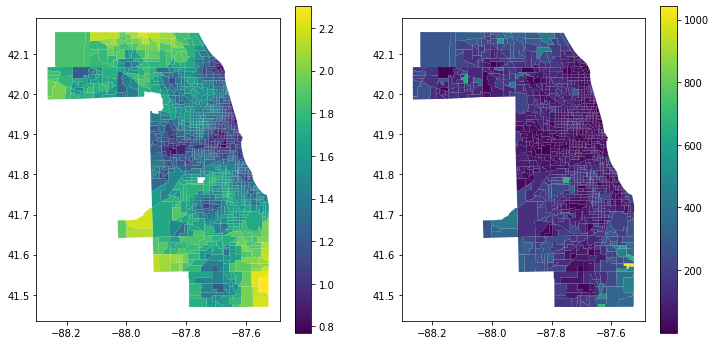

In [32]:
field1, field2 = "raam30_BEDS", "Cost"
figs, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
comparison.plot(ax=ax1, column=field1, legend=True)
comparison.plot(ax=ax2, column=field2, legend=True)

<AxesSubplot:>

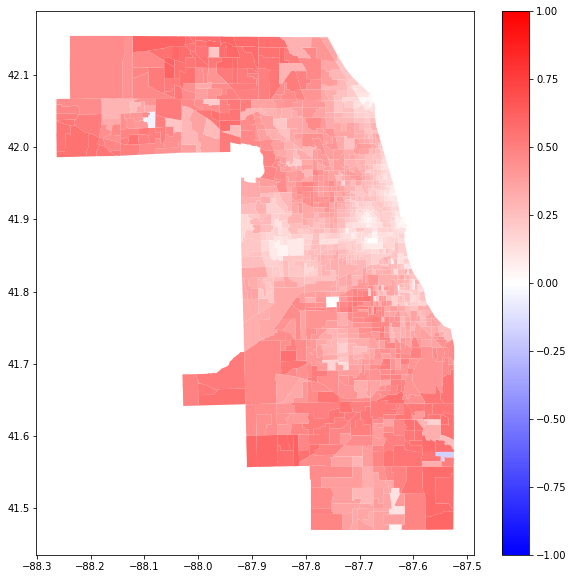

In [33]:
x = normalize_columns(comparison, [field1, field2])
x["Compare"] = x[field1] - x[field2]
x.plot(column="Compare", cmap="bwr", figsize=figsize, legend=True, vmin=-1, vmax=1)